# Tugas 1

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tempfile
import shutil

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

In [2]:
raw_data = pd.read_csv('burnout_dataset1.csv')
# Gunakan seluruh fitur numerik prediktor (keluarkan Person_ID dan Burnout_Score agar tidak terjadi leakage terhadap Burnout_Risk)
num_cols = [c for c in raw_data.select_dtypes(include=[np.number]).columns if c not in ['Person_ID', 'Burnout_Score']]
df_num = raw_data[num_cols + ['Burnout_Risk']].copy()
df_num[num_cols] = df_num[num_cols].fillna(df_num[num_cols].median())

# Ambil sampel stratified 3000 observasi agar pencarian grid 5-fold CV berjalan efisien seperti dataset voice.csv
data, _ = train_test_split(df_num, train_size=3000, random_state=42, stratify=df_num['Burnout_Risk'])
data = data.reset_index(drop=True)
data.head()

,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,Physical_Activity_Hours,Meditation_Minutes,Screen_Time_Hours,Social_Media_Hours,Gaming_Hours,Coffee_Cups_Per_Day,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Risk
0,30.0,1961.0,31,9.0,6.0,4.3,27.0,17.0,84.0,68,8.1,56.0,8.5,4.3,1.3,5,6.0,81.0,18,Low
1,53.0,3918.0,37,5.0,10.0,6.5,58.0,65.0,46.0,44,2.4,19.0,10.8,7.1,4.9,4,6.0,46.0,5,Moderate
2,43.0,7644.0,33,5.0,2.0,7.4,38.0,35.0,63.0,55,0.4,51.0,9.5,5.7,3.0,8,8.0,54.0,13,Moderate
3,32.0,5630.0,50,7.0,2.0,5.7,89.0,92.0,22.0,10,4.6,4.0,12.5,0.5,1.9,3,3.0,28.0,9,High
4,39.0,5803.0,54,3.0,1.0,7.9,46.0,60.0,60.0,57,7.9,57.0,9.7,1.1,3.2,4,3.0,70.0,21,Moderate


In [3]:
data.info()
print('Jumlah nilai kosong:', data.isna().sum().sum())
print(data['Burnout_Risk'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      3000 non-null   float64
 1   Monthly_Income_USD       3000 non-null   float64
 2   Work_Hours_Per_Week      3000 non-null   int64  
 3   Job_Satisfaction         3000 non-null   float64
 4   Work_Life_Balance        3000 non-null   float64
 5   Sleep_Hours              3000 non-null   float64
 6   Anxiety_Score            3000 non-null   float64
 7   Depression_Score         3000 non-null   float64
 8   Mood_Score               3000 non-null   float64
 9   Emotional_Stability      3000 non-null   int64  
 10  Physical_Activity_Hours  3000 non-null   float64
 11  Meditation_Minutes       3000 non-null   float64
 12  Screen_Time_Hours        3000 non-null   float64
 13  Social_Media_Hours       3000 non-null   float64
 14  Gaming_Hours             3000 non-n

In [4]:
X = data.drop(columns='Burnout_Risk')
y = data['Burnout_Risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print('Jumlah data latih:', len(X_train))
print('Jumlah data uji:', len(X_test))

Jumlah data latih: 2100
Jumlah data uji: 900


In [5]:
cachedir = tempfile.mkdtemp()
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('seleksi', SelectKBest(score_func=f_classif)),
    ('knn', KNeighborsClassifier())
], memory=cachedir)

parameter = {
    'seleksi__k': list(range(1, X_train.shape[1] + 1)),
    'knn__n_neighbors': list(range(1, 31))
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pencarian = GridSearchCV(
    pipeline, parameter, scoring='accuracy', cv=cv,
    n_jobs=2, return_train_score=True
)
pencarian.fit(X_train, y_train)
shutil.rmtree(cachedir, ignore_errors=True)

print('Parameter terbaik:', pencarian.best_params_)
print(f'Akurasi validasi silang terbaik: {pencarian.best_score_:.6f}')

Parameter terbaik: {'knn__n_neighbors': 22, 'seleksi__k': 5}
Akurasi validasi silang terbaik: 0.812381


In [6]:
hasil_cv = pd.DataFrame(pencarian.cv_results_)
hasil_cv['jumlah_fitur'] = hasil_cv['param_seleksi__k'].astype(int)
hasil_cv['k'] = hasil_cv['param_knn__n_neighbors'].astype(int)

hasil_cv[['jumlah_fitur', 'k', 'mean_train_score', 'mean_test_score', 'std_test_score']].sort_values(
    ['mean_test_score', 'jumlah_fitur', 'k'], ascending=[False, True, True]
).head(10)

,jumlah_fitur,k,mean_train_score,mean_test_score,std_test_score
403,5,22,0.819167,0.812381,0.018772
441,5,24,0.818452,0.812381,0.020057
498,5,27,0.818929,0.812381,0.018282
460,5,25,0.818929,0.811429,0.021998
422,5,23,0.818571,0.810952,0.017077
536,5,29,0.817857,0.810476,0.015836
365,5,20,0.820000,0.810000,0.018832
517,5,28,0.817738,0.810000,0.015533
479,5,26,0.818095,0.809048,0.018651
384,5,21,0.818810,0.808571,0.019319


In [7]:
model_terbaik = pencarian.best_estimator_
jumlah_fitur_terbaik = pencarian.best_params_['seleksi__k']
k_terbaik = pencarian.best_params_['knn__n_neighbors']
fitur_terbaik = X_train.columns[model_terbaik.named_steps['seleksi'].get_support()].tolist()

print('Jumlah fitur terbaik:', jumlah_fitur_terbaik)
print('Fitur yang digunakan:', ', '.join(fitur_terbaik))
print('Nilai k terbaik:', k_terbaik)

peringkat_fitur = pd.DataFrame({
    'Fitur': X_train.columns,
    'Skor ANOVA': model_terbaik.named_steps['seleksi'].scores_,
    'Dipilih': model_terbaik.named_steps['seleksi'].get_support()
})
peringkat_fitur.sort_values('Skor ANOVA', ascending=False)

Jumlah fitur terbaik: 5
Fitur yang digunakan: Anxiety_Score, Depression_Score, Mood_Score, Emotional_Stability, Productivity_Score
Nilai k terbaik: 22


,Fitur,Skor ANOVA,Dipilih
6,Anxiety_Score,2435.195808,True
9,Emotional_Stability,2281.060177,True
8,Mood_Score,2135.370344,True
7,Depression_Score,2108.733446,True
17,Productivity_Score,1932.485548,True
2,Work_Hours_Per_Week,444.672545,False
12,Screen_Time_Hours,89.272787,False
15,Coffee_Cups_Per_Day,66.608844,False
11,Meditation_Minutes,58.443512,False
10,Physical_Activity_Hours,44.754950,False


In [8]:
y_pred_train = model_terbaik.predict(X_train)
y_pred = model_terbaik.predict(X_test)

akurasi_train = accuracy_score(y_train, y_pred_train)
akurasi_test = accuracy_score(y_test, y_pred)

print(f'Akurasi data latih: {akurasi_train:.6f}')
print(f'Akurasi data uji: {akurasi_test:.6f}')
print('Confusion Matrix:')
print(confusion_matrix(y_test, y_pred, labels=['Low', 'Moderate', 'High']))
print('Laporan Klasifikasi:')
print(classification_report(y_test, y_pred, labels=['Low', 'Moderate', 'High']))

Akurasi data latih: 0.816190
Akurasi data uji: 0.815556
Confusion Matrix:
[[411  46   0]
 [ 52 175  39]
 [  0  29 148]]
Laporan Klasifikasi:
              precision    recall  f1-score   support

         Low       0.89      0.90      0.89       457
    Moderate       0.70      0.66      0.68       266
        High       0.79      0.84      0.81       177

    accuracy                           0.82       900
   macro avg       0.79      0.80      0.79       900
weighted avg       0.81      0.82      0.81       900



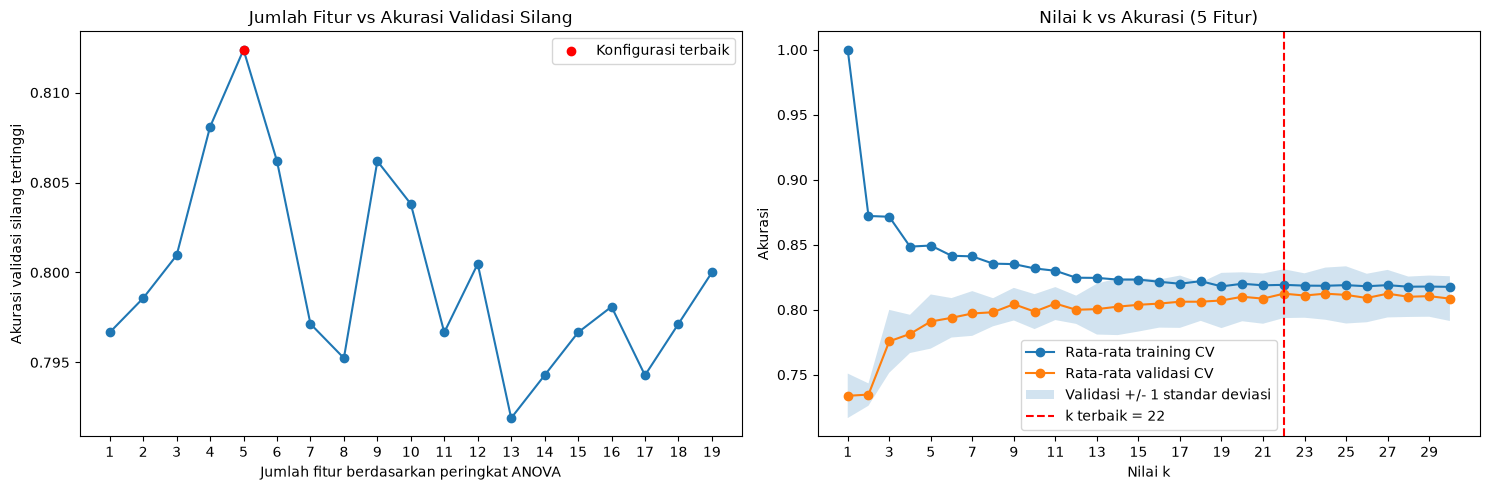

In [9]:
hasil_fitur = hasil_cv.groupby('jumlah_fitur')['mean_test_score'].max()
hasil_k = hasil_cv[hasil_cv['jumlah_fitur'] == jumlah_fitur_terbaik].sort_values('k')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(hasil_fitur.index, hasil_fitur.values, marker='o')
axes[0].scatter(jumlah_fitur_terbaik, pencarian.best_score_, color='red', zorder=3, label='Konfigurasi terbaik')
axes[0].set_xlabel('Jumlah fitur berdasarkan peringkat ANOVA')
axes[0].set_ylabel('Akurasi validasi silang tertinggi')
axes[0].set_title('Jumlah Fitur vs Akurasi Validasi Silang')
axes[0].set_xticks(range(1, X_train.shape[1] + 1))
axes[0].legend()

axes[1].plot(hasil_k['k'], hasil_k['mean_train_score'], marker='o', label='Rata-rata training CV')
axes[1].plot(hasil_k['k'], hasil_k['mean_test_score'], marker='o', label='Rata-rata validasi CV')
axes[1].fill_between(
    hasil_k['k'],
    hasil_k['mean_test_score'] - hasil_k['std_test_score'],
    hasil_k['mean_test_score'] + hasil_k['std_test_score'],
    alpha=0.2, label='Validasi +/- 1 standar deviasi'
)
axes[1].axvline(k_terbaik, color='red', linestyle='--', label=f'k terbaik = {k_terbaik}')
axes[1].set_xlabel('Nilai k')
axes[1].set_ylabel('Akurasi')
axes[1].set_title(f'Nilai k vs Akurasi ({jumlah_fitur_terbaik} Fitur)')
axes[1].set_xticks(range(1, 31, 2))
axes[1].legend()
plt.tight_layout()
plt.show()

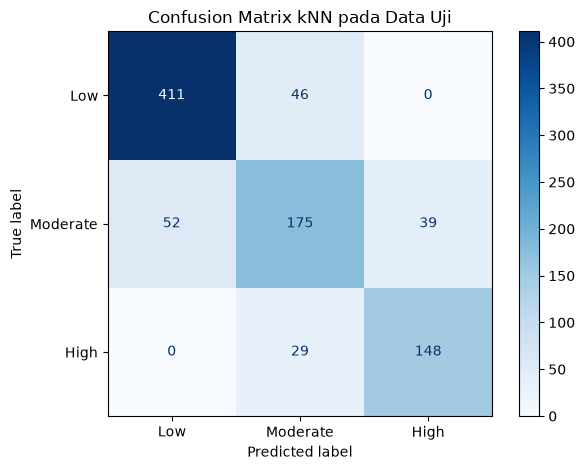

In [10]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=['Low', 'Moderate', 'High'], cmap='Blues', values_format='d'
)
plt.title('Confusion Matrix kNN pada Data Uji')
plt.tight_layout()
plt.show()

2. Percobaan menggunakan 1 sampai 19 fitur numerik teratas berdasarkan skor ANOVA dan nilai k dari 1 sampai 30. Standardisasi serta seleksi fitur dilakukan di dalam pipeline pada setiap fold agar tidak menggunakan informasi data validasi. Konfigurasi terbaik dari 570 kombinasi yang diuji menggunakan 5 fitur, yaitu Anxiety_Score, Depression_Score, Mood_Score, Emotional_Stability, dan Productivity_Score. Rata-rata akurasi validasi silang 5-fold sebesar 81,24%, lebih tinggi dibandingkan 80,00% untuk konfigurasi terbaik yang memakai seluruh 19 fitur.

3. Berdasarkan 5 fitur terpilih, nilai k terbaik adalah 22 karena menghasilkan rata-rata akurasi validasi silang tertinggi pada rentang k yang diuji. Pada nilai k yang terlalu kecil seperti k=1, akurasi training mencapai 100% tetapi akurasi validasi lebih rendah karena overfitting terhadap noise lokal. Akurasi pada data uji yang disisihkan mencapai 81,56%, konsisten dengan skor validasi silang.